# 01. Phân Tích Khám Phá Dữ Liệu (Exploratory Data Analysis - EDA)
**Đồ án môn học:** Hệ thống Hỗ trợ Ra quyết định (*Decision Support Systems* - `IS254.R11`)  
**Đề tài:** Cảnh báo sớm nguy cơ học tập của sinh viên bằng Dynamic Bayesian Network (DBN) và LSTM trên bộ dữ liệu OULAD  
**Tập dữ liệu phân tích:** `data/processed/clean_data.csv` (173.861 bản ghi × 28 thuộc tính)

---

### Mục tiêu của Notebook EDA
1. **Kiểm định chất lượng dữ liệu:** Xác nhận tính toàn vẹn, kiểu dữ liệu, miền giá trị và cấu trúc phân cấp (Sinh viên – Môn học – Bài đánh giá).
2. **Phân tích biến mục tiêu (`at_risk`) & Thiên lệch sống sót (*Survivorship Bias*):** So sánh tỷ lệ rủi ro ở cấp độ từng bài nộp và cấp độ lượt đăng ký môn học.
3. **Khám phá yếu tố nền tảng & môn học:** Xác định các môn học "điểm nóng" và nhóm nhân khẩu học có nguy cơ rớt/bỏ học cao.
4. **Phân tích kết quả đánh giá & hành vi nộp bài:** Đánh giá sức mạnh phân loại của điểm số (`score`), loại bài thi (`TMA`, `CMA`, `Exam`) và độ trễ hạn (`submission_delay`, `is_late`).
5. **Đánh giá nhóm đặc trưng tích lũy cảnh báo sớm:** Kiểm tra khả năng dự báo của lịch sử học tập (`prior_avg_score`, `prior_fail_count`, `score_progress`) theo tiến độ thời gian.
6. **Kiểm chứng giả định mô hình hóa cho Hệ DSS:** Thử nghiệm ngưỡng rời rạc hóa điểm số cho **DBN**, kiểm tra tương quan đa biến và rút ra kiến nghị kỹ thuật cho **LSTM** & **Dashboard DSS**.


## 1. Khởi tạo môi trường & Kiểm định chất lượng dữ liệu

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings('ignore')

# Cấu hình thẩm mỹ cho biểu đồ
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['font.size'] = 10
sns.set_palette('Set2')

# Đọc dữ liệu sạch từ thư mục data/processed
DATA_PATH = os.path.abspath(os.path.join('..', 'data', 'processed', 'clean_data.csv'))
df = pd.read_csv(DATA_PATH)

print(f"Đường dẫn dữ liệu : {DATA_PATH}")
print(f"Kích thước bảng   : {df.shape[0]:,} dòng x {df.shape[1]} cột")
print(f"Tổng giá trị Null : {df.isna().sum().sum()}")
print(f"Số dòng trùng lặp : {df.duplicated().sum()}")
print(f"Số SV duy nhất    : {df['id_student'].nunique():,} sinh viên")
n_enrollments = df.groupby(['code_module', 'code_presentation', 'id_student']).ngroups
print(f"Số lượt đăng ký   : {n_enrollments:,} lượt (Sinh viên x Môn x Kỳ học)")
print(f"Danh sách môn học : {sorted(df['code_module'].unique().tolist())}")
print(f"Danh sách học kỳ  : {sorted(df['code_presentation'].unique().tolist())}")

display(df.head())


Đường dẫn dữ liệu : c:\Users\ZiLing05\Desktop\IS254.R11\data\processed\clean_data.csv
Kích thước bảng   : 173,861 dòng x 28 cột
Tổng giá trị Null : 0
Số dòng trùng lặp : 0
Số SV duy nhất    : 23,345 sinh viên
Số lượt đăng ký   : 25,814 lượt (Sinh viên x Môn x Kỳ học)
Danh sách môn học : ['AAA', 'BBB', 'CCC', 'DDD', 'EEE', 'FFF', 'GGG']
Danh sách học kỳ  : ['2013B', '2013J', '2014B', '2014J']


,id_student,code_module,code_presentation,id_assessment,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,assessment_type,weight,assessment_order,submission_week,submission_delay,is_late,is_banked,score,is_passed_assessment,prior_assessments_count,prior_avg_score,prior_late_count,prior_fail_count,score_progress,final_result,at_risk
0,11391,AAA,2013J,1752,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,TMA,10.0,1,3,-1.0,0,0,78.0,1,0,0.0,0,0,0.0,Pass,0
1,11391,AAA,2013J,1753,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,TMA,20.0,2,8,-1.0,0,0,85.0,1,1,78.0,0,0,7.0,Pass,0
2,11391,AAA,2013J,1754,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,TMA,20.0,3,17,-2.0,0,0,80.0,1,2,81.5,0,0,-1.5,Pass,0
3,11391,AAA,2013J,1755,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,TMA,20.0,4,24,-2.0,0,0,85.0,1,3,81.0,0,0,4.0,Pass,0
4,11391,AAA,2013J,1756,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,TMA,30.0,5,31,-3.0,0,0,82.0,1,4,82.0,0,0,0.0,Pass,0


In [2]:
# Thống kê mô tả các thuộc tính định lượng
num_cols = [
    'num_of_prev_attempts', 'studied_credits', 'weight', 'assessment_order',
    'submission_week', 'submission_delay', 'is_late', 'is_banked', 'score',
    'is_passed_assessment', 'prior_assessments_count', 'prior_avg_score',
    'prior_late_count', 'prior_fail_count', 'score_progress', 'at_risk'
]
desc_df = df[num_cols].describe().T[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']].round(2)
display(desc_df)


,count,mean,std,min,25%,50%,75%,max
num_of_prev_attempts,173861.0,0.14,0.45,0.0,0.0,0.0,0.00,6.0
studied_credits,173861.0,76.77,37.34,30.0,60.0,60.0,90.00,630.0
weight,173861.0,12.75,17.88,0.0,0.0,9.0,18.00,100.0
assessment_order,173861.0,4.92,3.15,1.0,2.0,4.0,7.00,14.0
submission_week,173861.0,17.10,10.19,1.0,8.0,17.0,25.00,87.0
submission_delay,173861.0,-16.69,45.57,-246.0,-7.0,-1.0,2.00,372.0
is_late,173861.0,0.28,0.45,0.0,0.0,0.0,1.00,1.0
is_banked,173861.0,0.01,0.10,0.0,0.0,0.0,0.00,1.0
score,173861.0,75.73,18.94,0.0,65.0,80.0,90.00,100.0
is_passed_assessment,173861.0,0.96,0.21,0.0,1.0,1.0,1.00,1.0


## 2. Phân tích Biến mục tiêu (`at_risk`) & Hiện tượng Thiên lệch Sống sót (*Survivorship Bias*)

Trong bảng `clean_data.csv`, mỗi dòng tương ứng với **một bài đánh giá đã nộp** của sinh viên. Tuy nhiên, sinh viên bỏ học (`Withdrawn`) hoặc học yếu (`Fail`) thường ngừng nộp bài sớm, trong khi sinh viên đậu (`Pass` / `Distinction`) nộp đầy đủ các bài cho đến cuối kỳ. Do đó, cần đối chiếu phân phối nhãn ở cả **2 cấp độ**:
* **Cấp độ Bài nộp (*Assessment-level*):** 173.861 dòng.
* **Cấp độ Lượt đăng ký môn (*Enrollment-level*):** 25.814 lượt học duy nhất `(code_module, code_presentation, id_student)`.


Số bài nộp trung bình của từng nhóm kết quả cuối kỳ:


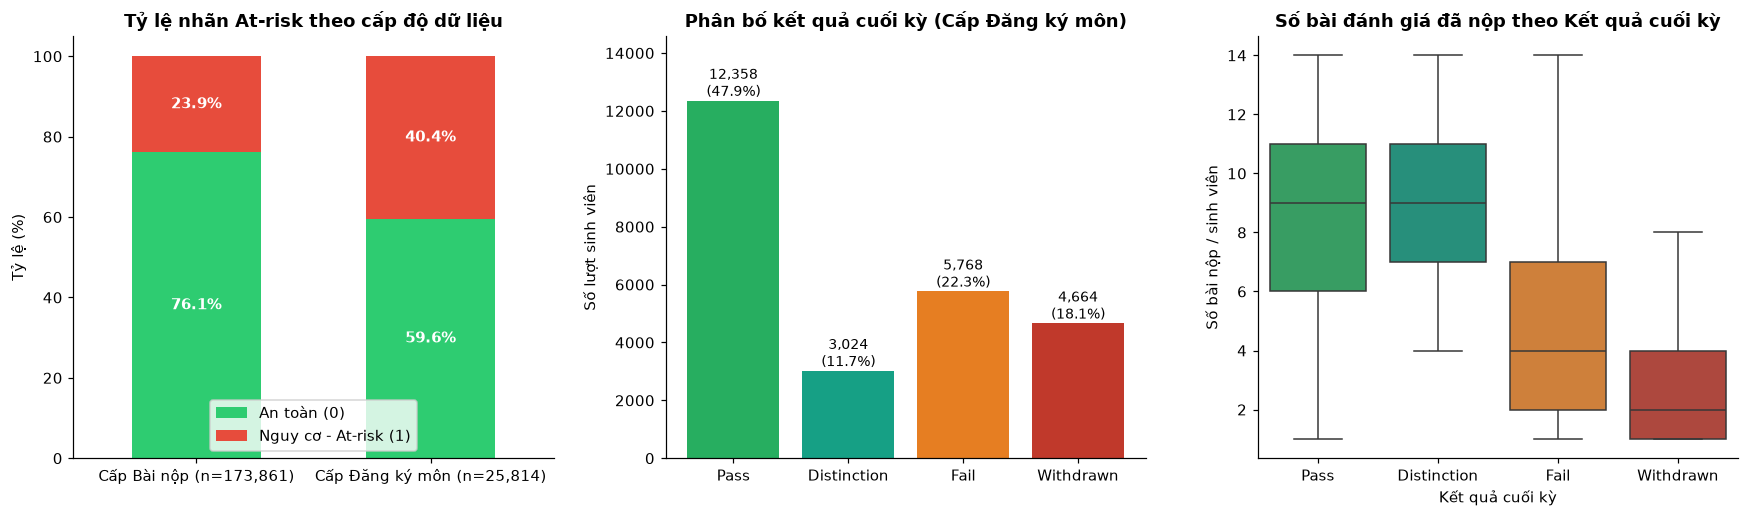

,count,mean,median,std
final_result,,,,
Pass,12358,8.58,9.0,2.98
Distinction,3024,8.71,9.0,2.87
Fail,5768,4.94,4.0,3.47
Withdrawn,4664,2.80,2.0,1.97


In [3]:
# Tổng hợp dữ liệu ở cấp độ lượt đăng ký môn (Enrollment-level)
enrollment_df = (
    df.groupby(['code_module', 'code_presentation', 'id_student'], as_index=False)
    .agg(
        total_submitted=('id_assessment', 'count'),
        mean_score=('score', 'mean'),
        late_count=('is_late', 'sum'),
        gender=('gender', 'first'),
        region=('region', 'first'),
        highest_education=('highest_education', 'first'),
        imd_band=('imd_band', 'first'),
        age_band=('age_band', 'first'),
        num_of_prev_attempts=('num_of_prev_attempts', 'first'),
        studied_credits=('studied_credits', 'first'),
        disability=('disability', 'first'),
        final_result=('final_result', 'first'),
        at_risk=('at_risk', 'first')
    )
)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

# 1. So sánh tỷ lệ at_risk ở 2 cấp độ
row_counts = df['at_risk'].value_counts(normalize=True).sort_index() * 100
enr_counts = enrollment_df['at_risk'].value_counts(normalize=True).sort_index() * 100
comp_df = pd.DataFrame({
    'Cấp Bài nộp (n=173,861)': [row_counts[0], row_counts[1]],
    'Cấp Đăng ký môn (n=25,814)': [enr_counts[0], enr_counts[1]]
}, index=['An toàn (0)', 'Nguy cơ - At-risk (1)'])

comp_df.T.plot(kind='bar', stacked=True, color=['#2ecc71', '#e74c3c'], ax=axes[0], width=0.55)
axes[0].set_title('Tỷ lệ nhãn At-risk theo cấp độ dữ liệu', fontweight='bold')
axes[0].set_ylabel('Tỷ lệ (%)')
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=0)
axes[0].legend(loc='lower center', frameon=True)
for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%.1f%%', label_type='center', color='white', fontweight='bold')

# 2. Phân bố 4 kết quả cuối kỳ (Enrollment-level)
order_res = ['Pass', 'Distinction', 'Fail', 'Withdrawn']
palette_res = ['#27ae60', '#16a085', '#e67e22', '#c0392b']
res_pct = enrollment_df['final_result'].value_counts().reindex(order_res)
bars = axes[1].bar(order_res, res_pct.values, color=palette_res)
axes[1].set_title('Phân bố kết quả cuối kỳ (Cấp Đăng ký môn)', fontweight='bold')
axes[1].set_ylabel('Số lượt sinh viên')
for b in bars:
    pct = b.get_height() / len(enrollment_df) * 100
    axes[1].annotate(f"{b.get_height():,}\n({pct:.1f}%)",
                     xy=(b.get_x() + b.get_width()/2, b.get_height()),
                     ha='center', va='bottom', fontsize=9)
axes[1].set_ylim(0, res_pct.max() * 1.18)

# 3. Số lượng bài nộp trung bình theo kết quả cuối kỳ
sns.boxplot(
    data=enrollment_df, x='final_result', y='total_submitted',
    order=order_res, palette=palette_res, ax=axes[2], showfliers=False
)
axes[2].set_title('Số bài đánh giá đã nộp theo Kết quả cuối kỳ', fontweight='bold')
axes[2].set_xlabel('Kết quả cuối kỳ')
axes[2].set_ylabel('Số bài nộp / sinh viên')

plt.tight_layout()
plt.show()

print("Số bài nộp trung bình của từng nhóm kết quả cuối kỳ:")
display(enrollment_df.groupby('final_result')['total_submitted'].agg(['count', 'mean', 'median', 'std']).reindex(order_res).round(2))


**Nhận xét quan trọng cho Hệ DSS:**
* **Chênh lệch tỷ lệ lớp (*Survivorship Bias*):** Ở cấp độ lượt đăng ký môn, tỷ lệ sinh viên gặp rủi ro thực tế lên tới **40.41%** (`Fail`: 22.3%, `Withdrawn`: 18.1%). Tuy nhiên, khi trải phẳng ra cấp độ bài nộp (`clean_data.csv`), tỷ lệ `at_risk = 1` giảm xuống còn **23.88%** vì nhóm `Pass`/`Distinction` nộp trung bình **8–9 bài/kỳ**, gấp đôi nhóm `Withdrawn` (chỉ nộp trung bình **~2.8 bài** trước khi bỏ cuộc).
* **Hàm ý huấn luyện mô hình:**
  1. Bắt buộc chia tập Train/Validation/Test theo **`GroupKFold` trên `id_student`** để cùng một sinh viên không xuất hiện ở cả hai tập.
  2. Cần sử dụng trọng số lớp (`class_weight='balanced'` hoặc `pos_weight` trong PyTorch BCE Loss) và đánh giá riêng theo từng mốc tuần $T$ để tránh thiên lệch về cuối kỳ.


## 3. Phân tích theo Môn học, Học kỳ và Nhân khẩu học

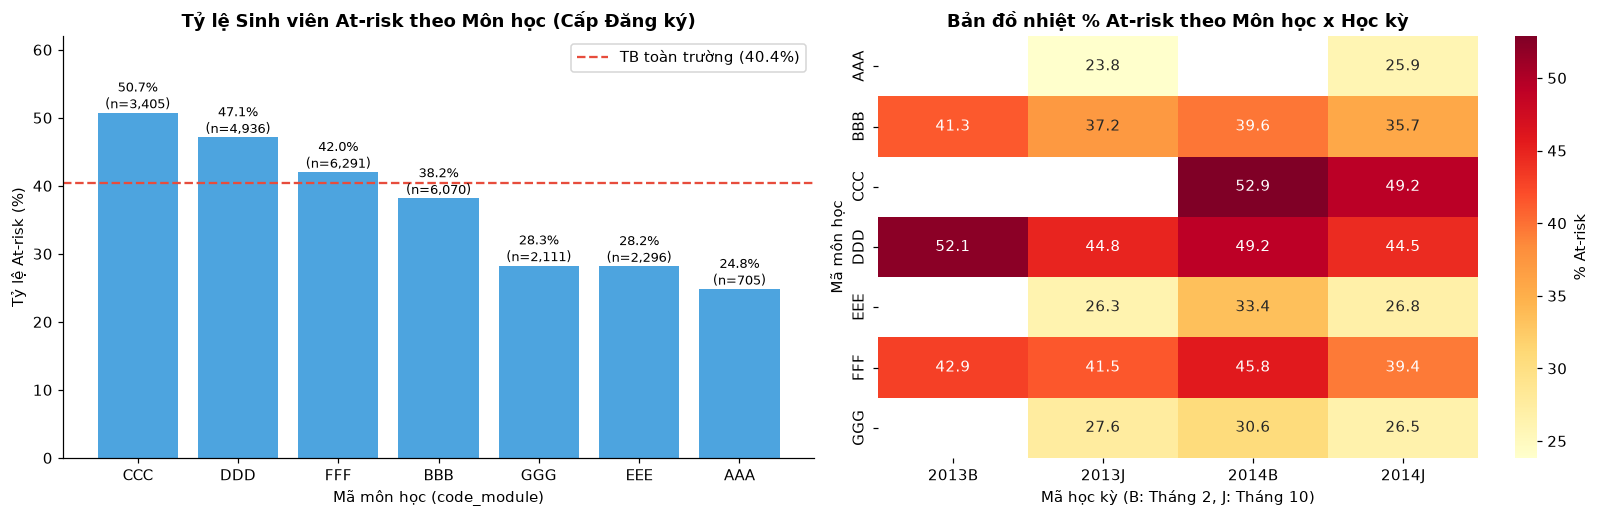

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))

# 1. Tỷ lệ At-risk và quy mô theo Môn học (code_module)
mod_stats = enrollment_df.groupby('code_module').agg(
    enrollments=('id_student', 'count'),
    at_risk_rate=('at_risk', lambda x: x.mean() * 100)
).sort_values('at_risk_rate', ascending=False)

ax1 = axes[0]
bars = ax1.bar(mod_stats.index, mod_stats['at_risk_rate'], color='#3498db', alpha=0.88)
ax1.axhline(enrollment_df['at_risk'].mean() * 100, color='#e74c3c', linestyle='--', label='TB toàn trường (40.4%)')
ax1.set_title('Tỷ lệ Sinh viên At-risk theo Môn học (Cấp Đăng ký)', fontweight='bold')
ax1.set_xlabel('Mã môn học (code_module)')
ax1.set_ylabel('Tỷ lệ At-risk (%)')
ax1.set_ylim(0, 62)
ax1.legend()
for bar, (_, row) in zip(bars, mod_stats.iterrows()):
    ax1.annotate(f"{row['at_risk_rate']:.1f}%\n(n={int(row['enrollments']):,})",
                 xy=(bar.get_x() + bar.get_width()/2, bar.get_height()),
                 ha='center', va='bottom', fontsize=8.5)

# 2. Tỷ lệ At-risk theo Học kỳ (code_presentation)
pres_stats = enrollment_df.groupby(['code_module', 'code_presentation'])['at_risk'].mean().unstack() * 100
sns.heatmap(pres_stats, annot=True, fmt='.1f', cmap='YlOrRd', cbar_kws={'label': '% At-risk'}, ax=axes[1])
axes[1].set_title('Bản đồ nhiệt % At-risk theo Môn học x Học kỳ', fontweight='bold')
axes[1].set_xlabel('Mã học kỳ (B: Tháng 2, J: Tháng 10)')
axes[1].set_ylabel('Mã môn học')

plt.tight_layout()
plt.show()


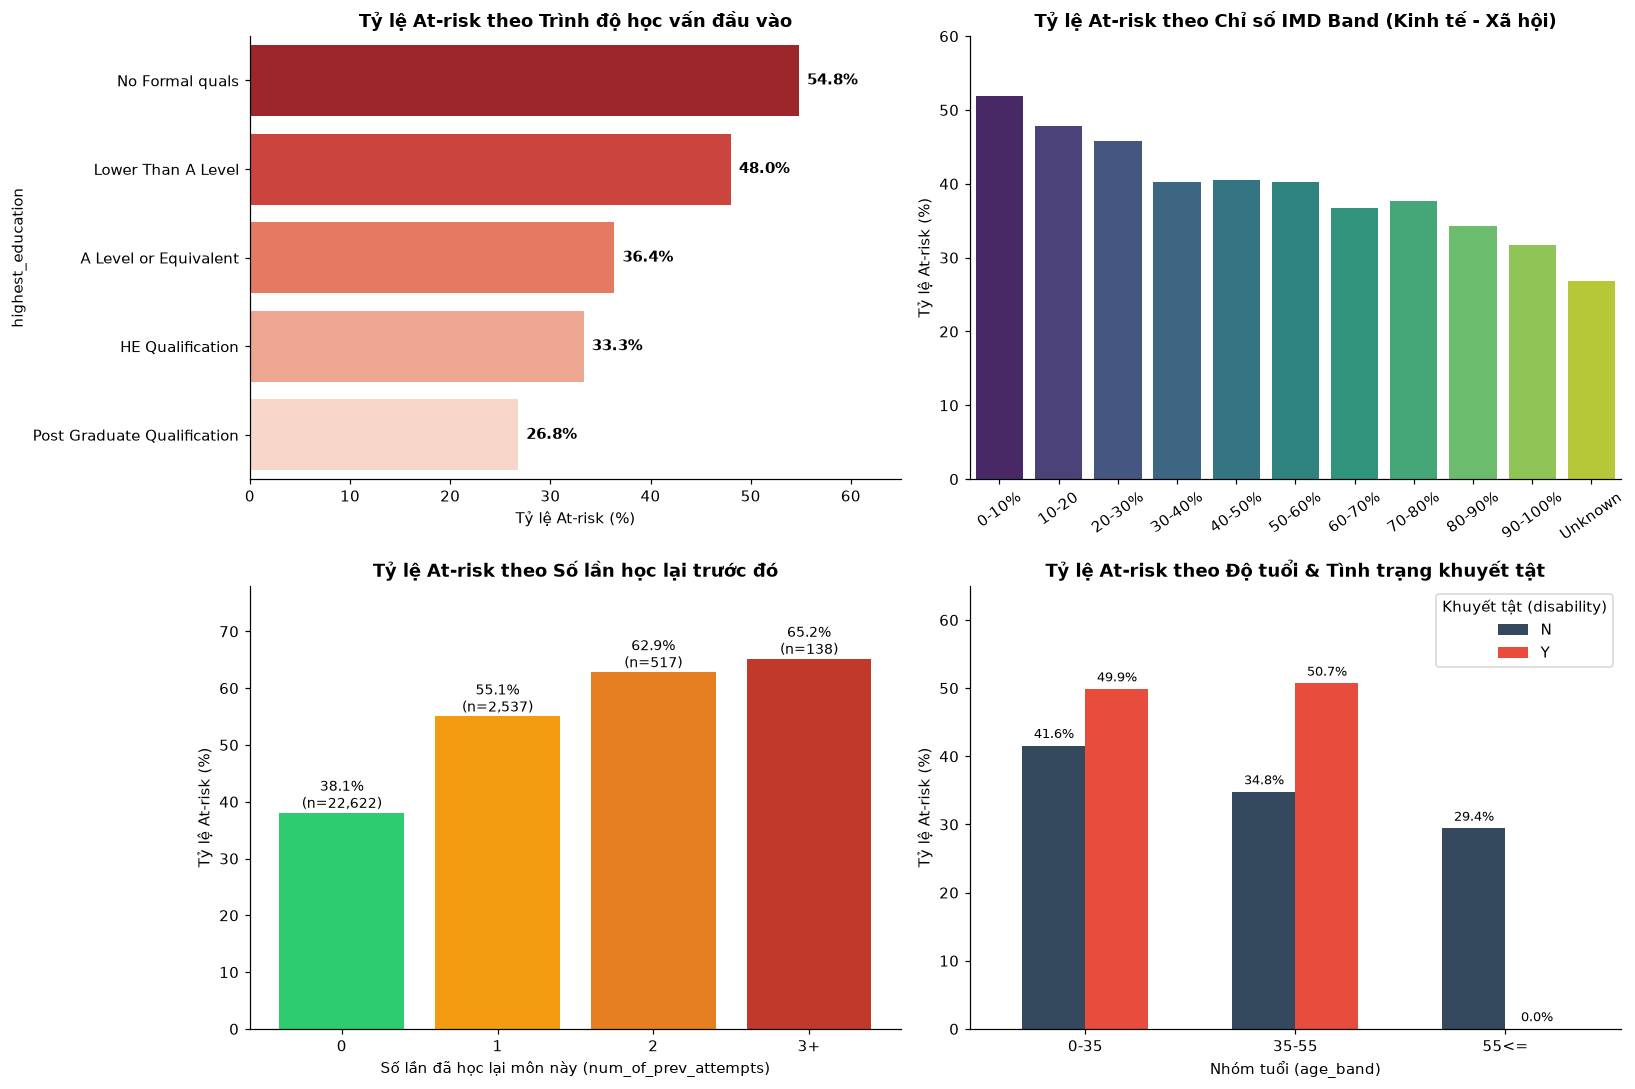

In [5]:
# Phân tích các yếu tố Nhân khẩu học & Nền tảng học tập (Tầng 1 & Tầng 2 của DBN)
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Trình độ học vấn cao nhất (highest_education)
edu_order = [
    'No Formal quals', 'Lower Than A Level',
    'A Level or Equivalent', 'HE Qualification', 'Post Graduate Qualification'
]
edu_stats = enrollment_df.groupby('highest_education')['at_risk'].mean().reindex(edu_order) * 100
sns.barplot(x=edu_stats.values, y=edu_stats.index, palette='Reds_r', ax=axes[0, 0])
axes[0, 0].set_title('Tỷ lệ At-risk theo Trình độ học vấn đầu vào', fontweight='bold')
axes[0, 0].set_xlabel('Tỷ lệ At-risk (%)')
axes[0, 0].set_xlim(0, 65)
for i, v in enumerate(edu_stats.values):
    axes[0, 0].text(v + 0.8, i, f"{v:.1f}%", va='center', fontweight='bold')

# 2. Chỉ số kinh tế - xã hội (imd_band)
imd_order = ['0-10%', '10-20', '20-30%', '30-40%', '40-50%', '50-60%', '60-70%', '70-80%', '80-90%', '90-100%', 'Unknown']
imd_present = [x for x in imd_order if x in enrollment_df['imd_band'].unique()]
imd_stats = enrollment_df.groupby('imd_band')['at_risk'].mean().reindex(imd_present) * 100
sns.barplot(x=imd_present, y=imd_stats.values, palette='viridis', ax=axes[0, 1])
axes[0, 1].set_title('Tỷ lệ At-risk theo Chỉ số IMD Band (Kinh tế - Xã hội)', fontweight='bold')
axes[0, 1].set_ylabel('Tỷ lệ At-risk (%)')
axes[0, 1].tick_params(axis='x', rotation=35)
axes[0, 1].set_ylim(0, 60)

# 3. Số lần học lại môn học (num_of_prev_attempts)
enrollment_df['prev_attempts_grp'] = enrollment_df['num_of_prev_attempts'].apply(lambda x: str(x) if x < 3 else '3+')
att_stats = enrollment_df.groupby('prev_attempts_grp').agg(
    n=('id_student', 'count'),
    risk=('at_risk', lambda x: x.mean() * 100)
)
bars = axes[1, 0].bar(att_stats.index, att_stats['risk'], color=['#2ecc71', '#f39c12', '#e67e22', '#c0392b'])
axes[1, 0].set_title('Tỷ lệ At-risk theo Số lần học lại trước đó', fontweight='bold')
axes[1, 0].set_xlabel('Số lần đã học lại môn này (num_of_prev_attempts)')
axes[1, 0].set_ylabel('Tỷ lệ At-risk (%)')
axes[1, 0].set_ylim(0, 78)
for b, (_, r) in zip(bars, att_stats.iterrows()):
    axes[1, 0].annotate(f"{r['risk']:.1f}%\n(n={int(r['n']):,})",
                        xy=(b.get_x() + b.get_width()/2, b.get_height()),
                        ha='center', va='bottom', fontsize=9)

# 4. Nhóm tuổi (age_band) kết hợp Tình trạng khuyết tật (disability)
age_dis = enrollment_df.groupby(['age_band', 'disability'])['at_risk'].mean().unstack() * 100
age_dis.plot(kind='bar', ax=axes[1, 1], color=['#34495e', '#e74c3c'], width=0.6)
axes[1, 1].set_title('Tỷ lệ At-risk theo Độ tuổi & Tình trạng khuyết tật', fontweight='bold')
axes[1, 1].set_xlabel('Nhóm tuổi (age_band)')
axes[1, 1].set_ylabel('Tỷ lệ At-risk (%)')
axes[1, 1].set_xticklabels(axes[1, 1].get_xticklabels(), rotation=0)
axes[1, 1].legend(title='Khuyết tật (disability)')
axes[1, 1].set_ylim(0, 65)
for container in axes[1, 1].containers:
    axes[1, 1].bar_label(container, fmt='%.1f%%', padding=3, fontsize=8.5)

plt.tight_layout()
plt.show()


**Phát hiện từ dữ liệu nền tảng ( củng cố thiết kế Tầng 1 & Tầng 2 của mạng DBN):**
1. **Sự phân hóa mạnh giữa các môn học (`code_module`):** Hai môn STEM `CCC` (**50.8%** At-risk) và `DDD` (**47.1%** At-risk) có tỷ lệ rớt/bỏ học cao gần gấp đôi so với `AAA` (**24.8%**), `EEE` (**28.2%**) và `GGG` (**28.3%**). Đưa `code_module` vào mô hình là bắt buộc.
2. **Nền tảng học vấn & Kinh tế xã hội:** Rủi ro giảm dần đều khi trình độ học vấn tăng — từ **54.8%** (`No Formal quals`) và **48.0%** (`Lower Than A Level`) xuống chỉ còn **26.8%** (`Post Graduate`). Tương tự, sinh viên ở vùng điều kiện kinh tế khó khăn nhất (`imd_band = 0-10%`) có rủi ro cao vượt trội so với vùng `90-100%`.
3. ** Tín hiệu cảnh báo sớm từ đầu kỳ (`num_of_prev_attempts` & `disability`):** Ngay cả khi học kỳ chưa bắt đầu ($T=0$), sinh viên từng trượt môn này 1 lần có xác suất rủi ro lên tới **55.1%** (tăng lên **62.9%–68.2%** nếu trượt $\ge 2$ lần), và sinh viên khuyết tật (`disability = Y`) có tỷ lệ rủi ro **50.1%** (so với 39.4%). Điều này ủng hộ mạnh mẽ **Giả thuyết H1** trong kế hoạch đồ án: *Ở các tuần đầu khi dữ liệu hành vi còn ít, cấu trúc tiên nghiệm của DBN vẫn dự báo tốt nhờ nhóm biến nền tảng*.


## 4. Phân tích Điểm số (`score`), Loại bài thi (`assessment_type`) & Hành vi nộp trễ

Thống kê chi tiết theo Loại bài đánh giá (assessment_type):


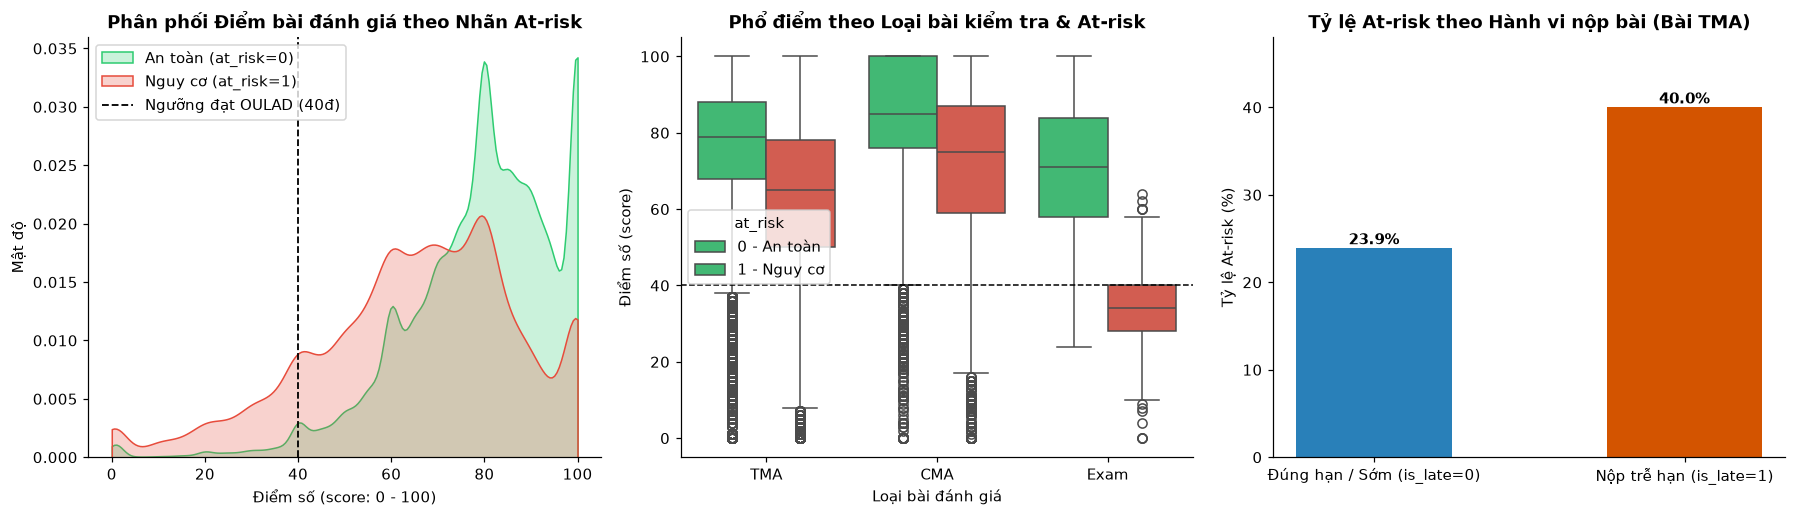

,so_bai_nop,diem_tb,ty_le_qua_bai,ty_le_nop_tre,ty_le_at_risk
assessment_type,,,,,
CMA,70503,81.03,97.55,46.77,20.79
Exam,4959,65.57,88.57,0.24,13.59
TMA,98399,72.44,94.46,16.58,26.60


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.8))

# 1. Phân phối phổ điểm (KDE) theo nhãn At-risk
sns.kdeplot(data=df[df['at_risk'] == 0], x='score', fill=True, color='#2ecc71', label='An toàn (at_risk=0)', ax=axes[0], clip=(0, 100))
sns.kdeplot(data=df[df['at_risk'] == 1], x='score', fill=True, color='#e74c3c', label='Nguy cơ (at_risk=1)', ax=axes[0], clip=(0, 100))
axes[0].axvline(40, color='black', linestyle='--', linewidth=1.2, label='Ngưỡng đạt OULAD (40đ)')
axes[0].set_title('Phân phối Điểm bài đánh giá theo Nhãn At-risk', fontweight='bold')
axes[0].set_xlabel('Điểm số (score: 0 - 100)')
axes[0].set_ylabel('Mật độ')
axes[0].legend()

# 2. Điểm số theo loại bài đánh giá (TMA, CMA, Exam) và nhãn At-risk
sns.boxplot(
    data=df, x='assessment_type', y='score', hue='at_risk',
    order=['TMA', 'CMA', 'Exam'], palette=['#2ecc71', '#e74c3c'], ax=axes[1]
)
axes[1].axhline(40, color='black', linestyle='--', linewidth=1)
axes[1].set_title('Phổ điểm theo Loại bài kiểm tra & At-risk', fontweight='bold')
axes[1].set_xlabel('Loại bài đánh giá')
axes[1].set_ylabel('Điểm số (score)')
axes[1].legend(title='at_risk', labels=['0 - An toàn', '1 - Nguy cơ'])

# 3. Tỷ lệ nộp trễ (is_late) của bài tự luận TMA theo nhóm rủi ro & điểm số
tma_df = df[df['assessment_type'] == 'TMA']
late_risk = tma_df.groupby('is_late')['at_risk'].mean() * 100
bars = axes[2].bar(['Đúng hạn / Sớm (is_late=0)', 'Nộp trễ hạn (is_late=1)'], late_risk.values, color=['#2980b9', '#d35400'], width=0.5)
axes[2].set_title('Tỷ lệ At-risk theo Hành vi nộp bài (Bài TMA)', fontweight='bold')
axes[2].set_ylabel('Tỷ lệ At-risk (%)')
axes[2].set_ylim(0, 48)
for b in bars:
    axes[2].annotate(f"{b.get_height():.1f}%",
                     xy=(b.get_x() + b.get_width()/2, b.get_height()),
                     ha='center', va='bottom', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()

print("Thống kê chi tiết theo Loại bài đánh giá (assessment_type):")
display(df.groupby('assessment_type').agg(
    so_bai_nop=('id_assessment', 'count'),
    diem_tb=('score', 'mean'),
    ty_le_qua_bai=('is_passed_assessment', lambda x: x.mean()*100),
    ty_le_nop_tre=('is_late', lambda x: x.mean()*100),
    ty_le_at_risk=('at_risk', lambda x: x.mean()*100)
).round(2))


**Phát hiện về Điểm số & Hành vi nộp bài:**
* **Khoảng cách điểm số rất rõ rệt:** Nhóm an toàn đạt trung bình **79.12 điểm**, cao hơn **14.21 điểm** so với nhóm nguy cơ (**64.91 điểm**). Mật độ điểm dưới ngưỡng đạt `40` và các đỉnh điểm thấp tập trung dày đặc ở nhóm `at_risk = 1`.
* **Khác biệt bản chất giữa `TMA` và `CMA`:**
  * **`TMA` (98.399 bài tự luận do trợ giảng chấm):** Phản ánh trung thực nhất kỷ luật học tập. Sinh viên nộp trễ bài `TMA` (`is_late = 1`) có xác suất rơi vào nhóm `at_risk` cao gấp gần **1.8 lần** so với nộp đúng hạn (**39.9%** so với **23.9%**).
  * **`CMA` (70.503 bài trắc nghiệm máy tính):** Điểm trung bình cao (**81.03đ**) và nhiều học phần ghi nhận ngày chốt điểm hàng loạt của hệ thống sau hạn vài ngày (`is_late = 46.8%`), do đó biến `is_late` nên được mô hình hóa tương tác cùng `assessment_type`!
  * **`Exam` (4.959 bài thi cuối kỳ):** Tỷ lệ `at_risk` chỉ còn **13.6%**, bởi những sinh viên trụ lại đến kỳ thi cuối kỳ đa phần đã vượt qua giai đoạn sàng lọc giữa kỳ.


## 5. Diễn biến theo Thời gian & Sức mạnh của Nhóm Đặc trưng Tích lũy Cảnh báo sớm

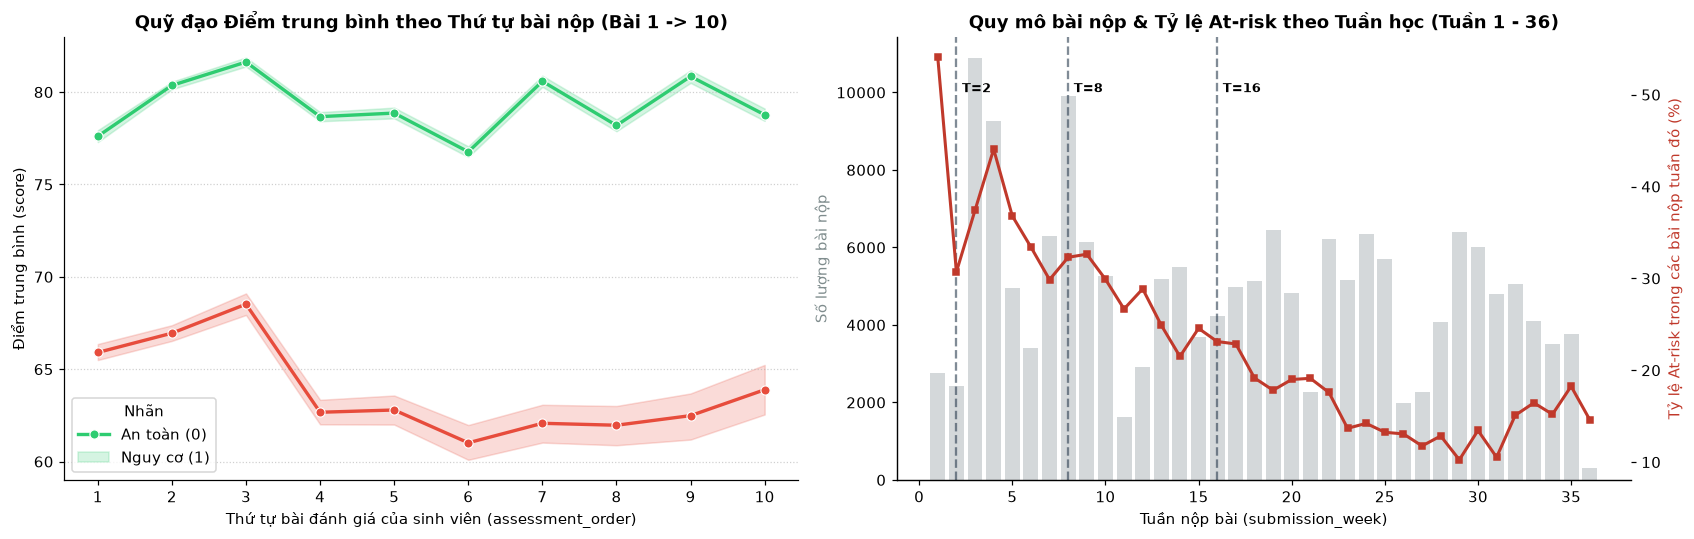

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15.5, 5))

# 1. Diễn biến điểm trung bình qua thứ tự bài đánh giá (assessment_order 1 -> 10)
ord_sub = df[df['assessment_order'] <= 10]
sns.lineplot(
    data=ord_sub, x='assessment_order', y='score', hue='at_risk',
    palette=['#2ecc71', '#e74c3c'], marker='o', linewidth=2.2, ax=axes[0]
)
axes[0].set_title('Quỹ đạo Điểm trung bình theo Thứ tự bài nộp (Bài 1 -> 10)', fontweight='bold')
axes[0].set_xlabel('Thứ tự bài đánh giá của sinh viên (assessment_order)')
axes[0].set_ylabel('Điểm trung bình (score)')
axes[0].set_xticks(range(1, 11))
axes[0].legend(title='Nhãn', labels=['An toàn (0)', 'Nguy cơ (1)'])
axes[0].grid(axis='y', linestyle=':', alpha=0.6)

# 2. Mật độ bài nộp và tỷ lệ At-risk theo Tuần nộp bài (submission_week <= 36)
wk_sub = df[(df['submission_week'] >= 1) & (df['submission_week'] <= 36)]
wk_stats = wk_sub.groupby('submission_week').agg(
    submissions=('id_assessment', 'count'),
    risk_rate=('at_risk', lambda x: x.mean() * 100)
)
ax2 = axes[1]
ax2.bar(wk_stats.index, wk_stats['submissions'], color='#bdc3c7', alpha=0.65, label='Số lượng bài nộp')
ax2.set_xlabel('Tuần nộp bài (submission_week)')
ax2.set_ylabel('Số lượng bài nộp', color='#7f8c8d')
ax2_twin = ax2.twinx()
ax2_twin.plot(wk_stats.index, wk_stats['risk_rate'], color='#c0392b', marker='s', markersize=4, linewidth=2, label='% At-risk')
ax2_twin.set_ylabel('Tỷ lệ At-risk trong các bài nộp tuần đó (%)', color='#c0392b')
ax2_twin.spines['top'].set_visible(False)
ax2.set_title('Quy mô bài nộp & Tỷ lệ At-risk theo Tuần học (Tuần 1 - 36)', fontweight='bold')

# Gắn mốc đánh giá T=2, T=8, T=16 theo kế hoạch đồ án
for t_mark in [2, 8, 16]:
    ax2.axvline(t_mark, color='#2c3e50', linestyle='--', alpha=0.6)
    ax2.text(t_mark + 0.3, wk_stats['submissions'].max()*0.92, f'T={t_mark}', fontsize=8.5, fontweight='bold')

plt.tight_layout()
plt.show()


Số bản ghi có lịch sử bài trước (prior_assessments_count > 0): 148,047 / 173,861 dòng (85.2%)


,prior_avg_score,prior_late_count,prior_fail_count,score_progress
0 - An toàn,79.770,1.171,0.067,-0.450
1 - Nguy cơ (At-risk),67.917,1.258,0.291,-3.344


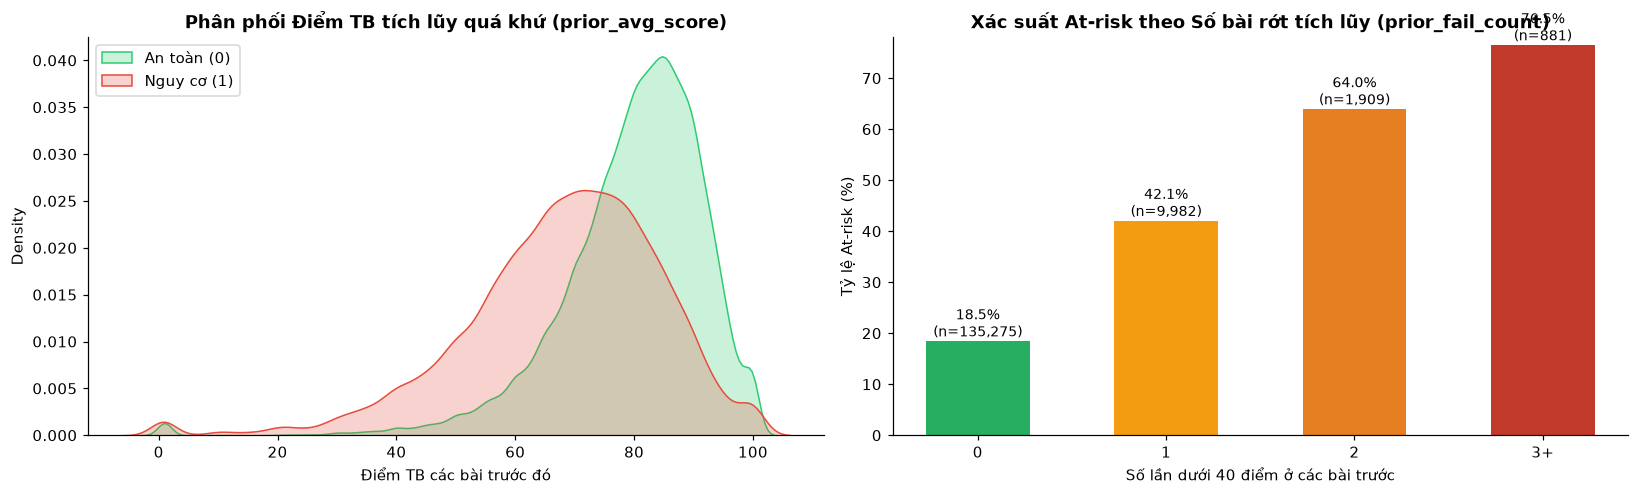

In [8]:
# Phân tích sâu nhóm đặc trưng tích lũy quá khứ (khi đã có ít nhất 1 bài trước đó: prior_assessments_count > 0)
prior_df = df[df['prior_assessments_count'] > 0].copy()

print(f"Số bản ghi có lịch sử bài trước (prior_assessments_count > 0): {len(prior_df):,} / {len(df):,} dòng ({len(prior_df)/len(df)*100:.1f}%)")
summary_prior = prior_df.groupby('at_risk')[
    ['prior_avg_score', 'prior_late_count', 'prior_fail_count', 'score_progress']
].mean().round(3)
summary_prior.index = ['0 - An toàn', '1 - Nguy cơ (At-risk)']
display(summary_prior)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))

# Phân phối prior_avg_score
sns.kdeplot(data=prior_df[prior_df['at_risk'] == 0], x='prior_avg_score', fill=True, color='#2ecc71', label='An toàn (0)', ax=axes[0])
sns.kdeplot(data=prior_df[prior_df['at_risk'] == 1], x='prior_avg_score', fill=True, color='#e74c3c', label='Nguy cơ (1)', ax=axes[0])
axes[0].set_title('Phân phối Điểm TB tích lũy quá khứ (prior_avg_score)', fontweight='bold')
axes[0].set_xlabel('Điểm TB các bài trước đó')
axes[0].legend()

# Tỷ lệ At-risk tăng theo số bài thi rớt trước đó (prior_fail_count)
prior_df['fail_grp'] = prior_df['prior_fail_count'].apply(lambda x: str(x) if x < 3 else '3+')
fail_risk = prior_df.groupby('fail_grp').agg(n=('id_student', 'count'), risk=('at_risk', lambda x: x.mean()*100))
bars = axes[1].bar(fail_risk.index, fail_risk['risk'], color=['#27ae60', '#f39c12', '#e67e22', '#c0392b'], width=0.55)
axes[1].set_title('Xác suất At-risk theo Số bài rớt tích lũy (prior_fail_count)', fontweight='bold')
axes[1].set_xlabel('Số lần dưới 40 điểm ở các bài trước')
axes[1].set_ylabel('Tỷ lệ At-risk (%)')
axes[1].set_ylim(0, 78)
for b, (_, r) in zip(bars, fail_risk.iterrows()):
    axes[1].annotate(f"{r['risk']:.1f}%\n(n={int(r['n']):,})",
                     xy=(b.get_x() + b.get_width()/2, b.get_height()),
                     ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()


**Phát hiện quan trọng về chuỗi thời gian & Lưu ý kỹ thuật khi đưa vào Model:**
1. **Phân kỳ quỹ đạo điểm từ rất sớm:** Ngay từ bài kiểm tra số 1 (`assessment_order = 1`), điểm trung bình của nhóm `at_risk = 1` đã thấp hơn hẳn nhóm an toàn (~65đ so với ~78đ), và khoảng cách này **ngày càng nới rộng** ở các bài tiếp theo (`score_progress = -3.34` điểm ở nhóm nguy cơ so với `-0.45` ở nhóm an toàn). Đây là tín hiệu chuỗi lý tưởng để mạng **LSTM** khai thác (củng cố **Giả thuyết H2**).
2. **Sức báo động mạnh của `prior_fail_count`:** Chỉ cần sinh viên rớt 1 bài đánh giá trước đó (`prior_fail_count = 1`), nguy cơ trượt/bỏ môn đã tăng vọt gấp đôi lên **46.4%**, và chạm ngưỡng **>63%** nếu rớt từ 2 bài trở lên.
3. **⚠️ Lưu ý kỹ thuật quan trọng phát hiện nhờ EDA:** Ở bài đầu tiên (`prior_assessments_count == 0`, chiếm 14.8% dữ liệu), `prior_avg_score` đang được gán mặc định bằng `0.0`. Nếu đưa trực tiếp vào Logistic Regression / Neural Network mà không kèm cờ `has_prior = (prior_assessments_count > 0)`, mô hình tuyến tính sẽ hiểu nhầm `0.0` là "sinh viên bị 0 điểm ở các bài trước"! Khi loại bỏ bài đầu tiên, tương quan âm giữa `prior_avg_score` và `at_risk` mạnh lên từ `-0.276` lên **`-0.343`**.


## 6. Ma trận Tương quan & Kiểm chứng Ngưỡng Rời rạc hóa cho Mạng DBN

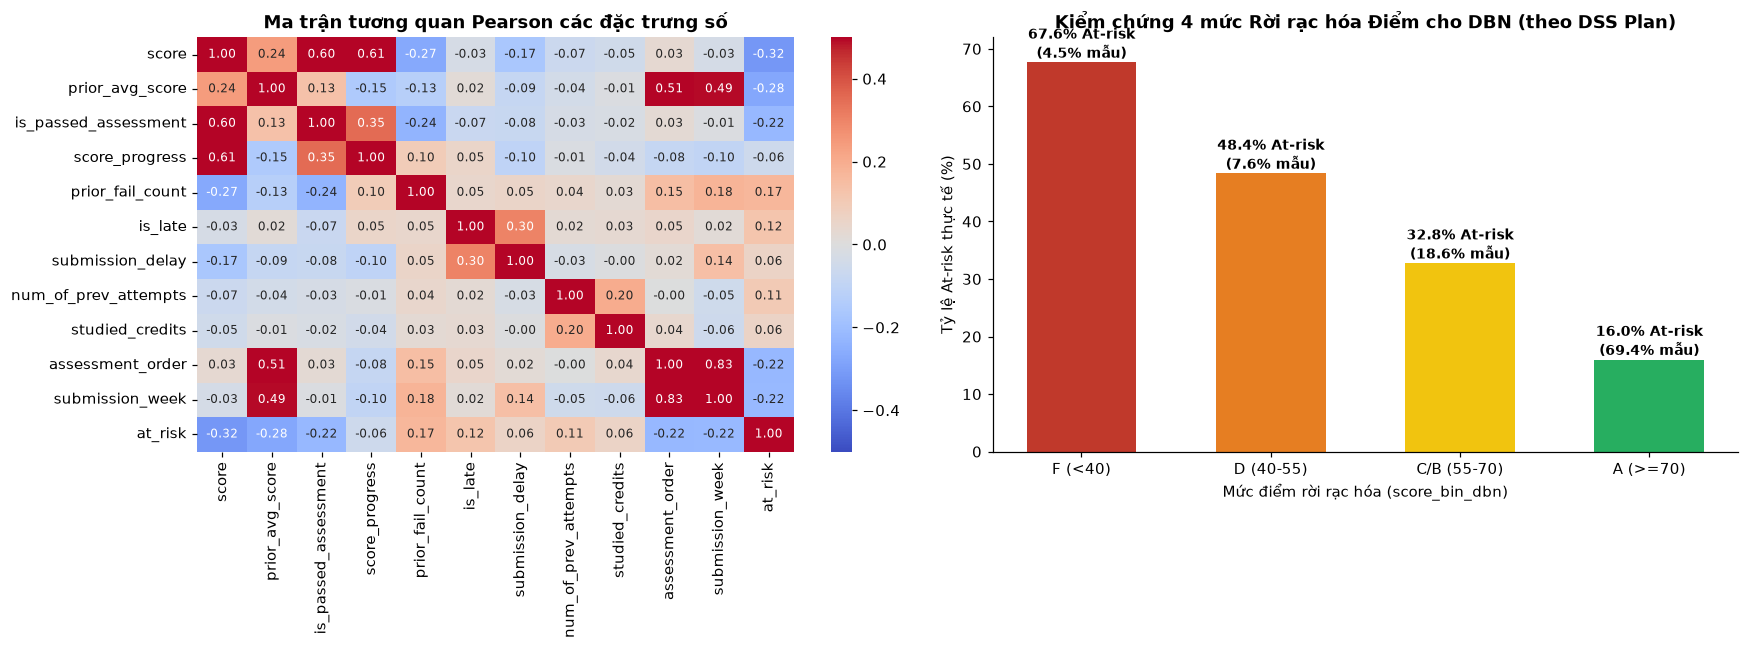

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Ma trận tương quan giữa các biến chính
corr_cols = [
    'score', 'prior_avg_score', 'is_passed_assessment', 'score_progress',
    'prior_fail_count', 'is_late', 'submission_delay', 'num_of_prev_attempts',
    'studied_credits', 'assessment_order', 'submission_week', 'at_risk'
]
corr_mat = df[corr_cols].corr()
sns.heatmap(corr_mat, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-0.5, vmax=0.5,
            annot_kws={'size': 8}, ax=axes[0])
axes[0].set_title('Ma trận tương quan Pearson các đặc trưng số', fontweight='bold')

# 2. Kiểm chứng ngưỡng rời rạc hóa điểm số cho DBN theo Kế hoạch đồ án (<40, 40-55, 55-70, >=70)
bins = [-1, 39.999, 54.999, 69.999, 100.0]
labels = ['F (<40)', 'D (40-55)', 'C/B (55-70)', 'A (>=70)']
df['score_bin_dbn'] = pd.cut(df['score'], bins=bins, labels=labels)

bin_stats = df.groupby('score_bin_dbn', observed=False).agg(
    count=('id_assessment', 'count'),
    at_risk_rate=('at_risk', lambda x: x.mean() * 100)
)

bars = axes[1].bar(bin_stats.index.astype(str), bin_stats['at_risk_rate'],
                   color=['#c0392b', '#e67e22', '#f1c40f', '#27ae60'], width=0.58)
axes[1].set_title('Kiểm chứng 4 mức Rời rạc hóa Điểm cho DBN (theo DSS Plan)', fontweight='bold')
axes[1].set_xlabel('Mức điểm rời rạc hóa (score_bin_dbn)')
axes[1].set_ylabel('Tỷ lệ At-risk thực tế (%)')
axes[1].set_ylim(0, 72)
for b, (_, r) in zip(bars, bin_stats.iterrows()):
    pct_share = r['count'] / len(df) * 100
    axes[1].annotate(f"{r['at_risk_rate']:.1f}% At-risk\n({pct_share:.1f}% mẫu)",
                     xy=(b.get_x() + b.get_width()/2, b.get_height()),
                     ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()


---

## 7. Tổng kết Kết quả EDA & Đề xuất Kỹ thuật cho Giai đoạn Xây dựng Mô hình

Từ quá trình phân tích khám phá toàn diện trên **173.861 bản ghi** (`25.814` lượt đăng ký của `23.345` sinh viên), nhóm rút ra **6 kết luận trọng tâm** định hướng trực tiếp cho các bước tiếp theo của đồ án DSS:

| STT | Phát hiện từ EDA | Ý nghĩa & Hành động kỹ thuật trong Hệ DSS |
| :-: | :--- | :--- |
| **1** | **Dữ liệu hoàn toàn sạch (0% Null, 0 Duplicate)** và đạt quy mô lớn (`173.861` dòng $\gg 40.000$ dòng yêu cầu). | Đủ điều kiện huấn luyện các mô hình học sâu (LSTM) và ước lượng bảng xác suất có điều kiện (CPT) của mạng DBN mà không lo thưa dữ liệu. |
| **2** | **Thiên lệch sống sót (*Survivorship Bias*):** Tỷ lệ `at_risk` là **40.41%** theo lượt đăng ký nhưng chỉ chiếm **23.88%** số dòng bài nộp (do SV bỏ học ngừng nộp bài sớm). | Chia dữ liệu bằng `GroupKFold` / `StratifiedGroupKFold` theo `id_student`; áp dụng `class_weight` khi huấn luyện và ưu tiên theo dõi chỉ số **Recall**, **F1-Score**, **AUC-PR** cho lớp `At-risk`. |
| **3** | **4 ngưỡng rời rạc hóa điểm số (`<40`, `40–55`, `55–70`, `>=70`) phân tách rủi ro đơn điệu hoàn hảo:** Tỷ lệ `at_risk` giảm bậc thang từ **67.6%** → **48.4%** → **32.8%** → **16.0%**. | Xác nhận tính đúng đắn của thiết kế ngưỡng rời rạc hóa trong `docs/DSS_plan.docx` để đưa vào học cấu trúc và tham số cho **Dynamic Bayesian Network (`pgmpy`)**. |
| **4** | **Giá trị mặc định `prior_avg_score = 0.0` ở bài nộp đầu tiên (`assessment_order = 1`)** gây nhiễu nhẹ cho tương quan tuyến tính. | Thêm biến cờ nhị phân `has_prior_assessment` (hoặc dùng masking cho LSTM / node trạng thái riêng cho DBN) khi huấn luyện mô hình dự báo ở tuần đầu. |
| **5** | **Tương tác mạnh giữa `is_late` và `assessment_type`:** Nộp trễ bài tự luận `TMA` làm tăng vọt rủi ro lên **39.9%**, trong khi `CMA` có cơ chế chốt điểm tự động cuối đợt. | Cần mã hóa đặc trưng kết hợp (`is_late × assessment_type`) hoặc tách riêng điểm/độ trễ của `TMA` và `CMA` khi tổng hợp đặc trưng theo tuần. |
| **6** | **Bổ sung luồng tương tác LMS (`studentVle.csv`):** Hiện `clean_data.csv` mới phản ánh khía cạnh *Kết quả đánh giá* (Assessment), chưa có số lượt click hàng tuần (`Clicks_wk`). | Ở các tuần chưa có hạn nộp bài kiểm tra (ví dụ $T=1, 2$), tích hợp thêm tổng lượt click từ `data/raw/studentVle.csv` sẽ giúp **Dashboard DSS** phân biệt rõ sinh viên *"ít truy cập LMS"* với sinh viên *"chăm truy cập nhưng điểm thấp"*. |
